In [2]:
import sys

sys.path.append("..")

import pandas as pd
from src.data_collection import get_stock_prices

In [3]:
ticker = ["MSFT", "AAPL", "JPM", "JNJ", "XOM", "WMT"]

stock_data = {t: get_stock_prices(t, max_records=1250) for t in ticker}

In [4]:
for ticker in stock_data:

    stock_data[ticker]["date"] = pd.to_datetime(
        stock_data[ticker]["date"]
    )

    stock_data[ticker] = (
        stock_data[ticker]
        .sort_values("date")
        .reset_index(drop=True)
    )

    stock_data[ticker]["daily_return"] = (
        stock_data[ticker]["close"].pct_change()
    )

In [5]:
returns = pd.DataFrame()

for ticker, df in stock_data.items():
    returns[ticker] = df.set_index("date")["daily_return"]

returns.shape

(1250, 6)

In [6]:
returns.isnull().sum()

MSFT    1
AAPL    1
JPM     1
JNJ     1
XOM     1
WMT     1
dtype: int64

In [7]:
returns = returns.dropna()

returns.describe()

,MSFT,AAPL,JPM,JNJ,XOM,WMT
count,1249.000000,1249.000000,1249.000000,1249.000000,1249.000000,1249.000000
mean,0.000611,0.000856,0.000672,0.000489,0.000918,0.000798
std,0.017778,0.017667,0.015404,0.011128,0.016783,0.014178
min,-0.099931,-0.092456,-0.080502,-0.075917,-0.078853,-0.113758
25%,-0.008466,-0.007756,-0.007265,-0.005441,-0.008719,-0.006339
50%,0.000473,0.001124,0.001163,0.000400,0.001262,0.001091
75%,0.010125,0.009720,0.009031,0.006564,0.011223,0.008219
max,0.155067,0.153288,0.115445,0.061932,0.064113,0.095488


In [8]:
cumulative_returns = (1 + returns).cumprod()

In [9]:
for ticker, df in stock_data.items():
    print(ticker, "duplicate rows:", df.duplicated().sum())

MSFT duplicate rows: 0
AAPL duplicate rows: 0
JPM duplicate rows: 0
JNJ duplicate rows: 0
XOM duplicate rows: 0
WMT duplicate rows: 0


In [10]:
for ticker, df in stock_data.items():

    invalid_high_open = (df["high"] < df["open"]).sum()
    invalid_high_close = (df["high"] < df["close"]).sum()
    invalid_low_open = (df["low"] > df["open"]).sum()
    invalid_low_close = (df["low"] > df["close"]).sum()

    print(f"\n{ticker}")
    print("High < Open:", invalid_high_open)
    print("High < Close:", invalid_high_close)
    print("Low > Open:", invalid_low_open)
    print("Low > Close:", invalid_low_close)


MSFT
High < Open: 0
High < Close: 0
Low > Open: 0
Low > Close: 0

AAPL
High < Open: 0
High < Close: 0
Low > Open: 0
Low > Close: 0

JPM
High < Open: 1
High < Close: 0
Low > Open: 0
Low > Close: 0

JNJ
High < Open: 0
High < Close: 0
Low > Open: 1
Low > Close: 0

XOM
High < Open: 1
High < Close: 0
Low > Open: 0
Low > Close: 0

WMT
High < Open: 0
High < Close: 0
Low > Open: 1
Low > Close: 0


In [11]:
for ticker, df in stock_data.items():

    print(
        ticker,
        "negative prices:",
        (df[["open", "high", "low", "close"]] < 0).sum().sum()
    )

    print(
        ticker,
        "negative volume:",
        (df["volume"] < 0).sum()
    )

MSFT negative prices: 0
MSFT negative volume: 0
AAPL negative prices: 0
AAPL negative volume: 0
JPM negative prices: 0
JPM negative volume: 0
JNJ negative prices: 0
JNJ negative volume: 0
XOM negative prices: 0
XOM negative volume: 0
WMT negative prices: 0
WMT negative volume: 0


In [12]:
for ticker, df in stock_data.items():

    is_sorted = df["date"].is_monotonic_increasing

    print(ticker, "chronological:", is_sorted)

MSFT chronological: True
AAPL chronological: True
JPM chronological: True
JNJ chronological: True
XOM chronological: True
WMT chronological: True


VISUALIZATION

In [13]:
import matplotlib.pyplot as plt

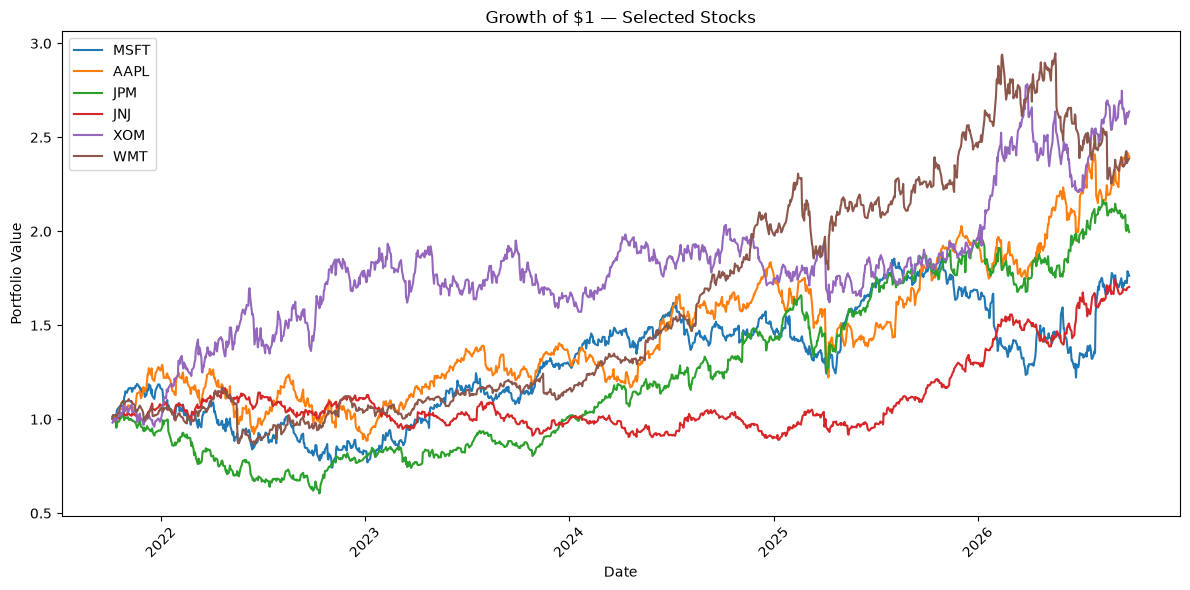

In [14]:
plt.figure(figsize=(12, 6))

for ticker in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[ticker],
        label=ticker
    )

plt.title("Growth of $1 — Selected Stocks")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

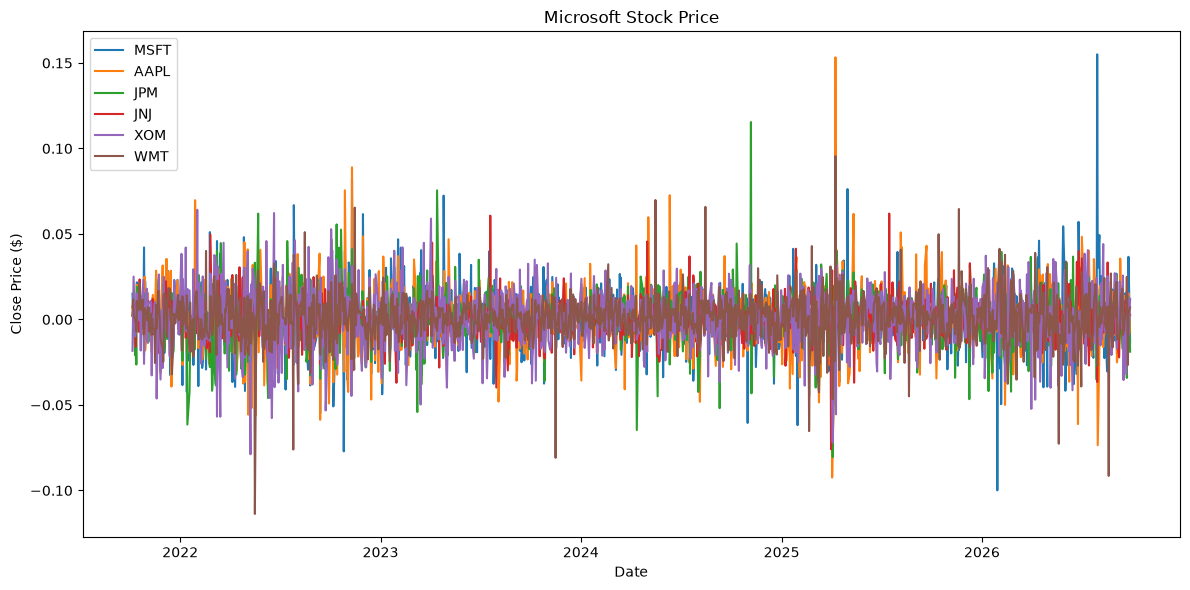

In [15]:
plt.figure(figsize=(12, 6))

for ticker in returns.columns:
    plt.plot(
        returns.index,
        returns[ticker],
        label=ticker
    )

plt.xlabel('Date')
plt.ylabel('Close Price ($)')
plt.title('Microsoft Stock Price')

# plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()

In [16]:
performance = pd.DataFrame({
    "Annualized Return": returns.mean() * 252,
    "Annualized Volatility": returns.std() * (252 ** 0.5)
})

performance['Cumulative Return'] = cumulative_returns.iloc[-1] - 1

performance


,Annualized Return,Annualized Volatility,Cumulative Return
MSFT,0.154032,0.282211,0.763471
AAPL,0.215683,0.280461,1.398129
JPM,0.169308,0.244533,0.995672
JNJ,0.123152,0.176655,0.704161
XOM,0.231297,0.266426,1.637455
WMT,0.201123,0.225071,1.387571


In [17]:
performance_display = performance.copy()

performance_display[
    ["Annualized Return", "Annualized Volatility", "Cumulative Return"]
] *= 100

performance_display = performance_display.round(2)

performance_display = performance_display.astype(str) + "%"

performance_display

,Annualized Return,Annualized Volatility,Cumulative Return
MSFT,15.4%,28.22%,76.35%
AAPL,21.57%,28.05%,139.81%
JPM,16.93%,24.45%,99.57%
JNJ,12.32%,17.67%,70.42%
XOM,23.13%,26.64%,163.75%
WMT,20.11%,22.51%,138.76%


In [18]:
performance["Sharpe Ratio of 0% risk-free rate"] = (
    performance["Annualized Return"] /
    performance["Annualized Volatility"]
)

performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate
MSFT,0.154,0.282,0.763,0.546
AAPL,0.216,0.280,1.398,0.769
JPM,0.169,0.245,0.996,0.692
JNJ,0.123,0.177,0.704,0.697
XOM,0.231,0.266,1.637,0.868
WMT,0.201,0.225,1.388,0.894


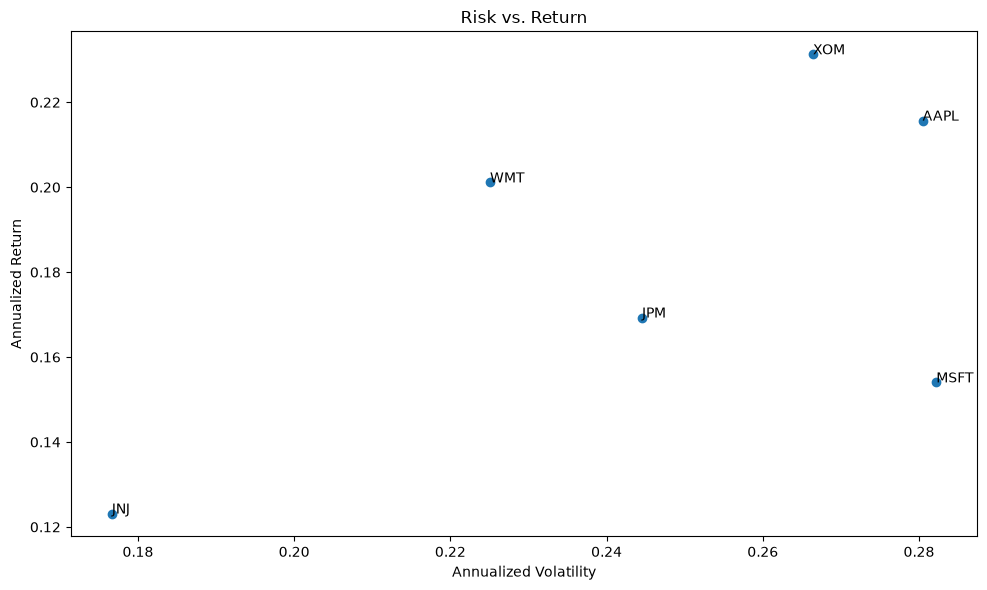

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(
    performance["Annualized Volatility"],
    performance["Annualized Return"]
)

for ticker in performance.index:
    plt.annotate(
        ticker,
        (
            performance.loc[ticker, "Annualized Volatility"],
            performance.loc[ticker, "Annualized Return"]
        )
    )

plt.title("Risk vs. Return")
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")

plt.tight_layout()
plt.show()

In [20]:
running_max = cumulative_returns.cummax()

drawdown = (
    cumulative_returns - running_max
) / running_max

max_drawdown = drawdown.min()

performance["Maximum Drawdown"] = max_drawdown

performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown
MSFT,0.154,0.282,0.763,0.546,-0.376
AAPL,0.216,0.280,1.398,0.769,-0.334
JPM,0.169,0.245,0.996,0.692,-0.406
JNJ,0.123,0.177,0.704,0.697,-0.236
XOM,0.231,0.266,1.637,0.868,-0.207
WMT,0.201,0.225,1.388,0.894,-0.260


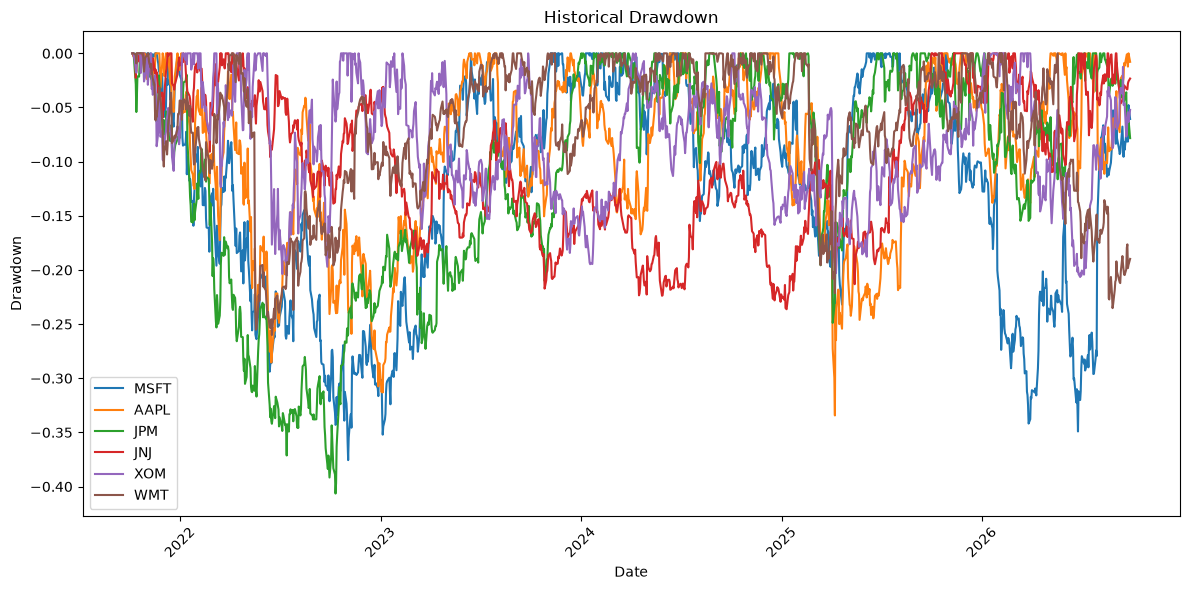

In [21]:
plt.figure(figsize=(12, 6))

for ticker in drawdown.columns:
    plt.plot(
        drawdown.index,
        drawdown[ticker],
        label=ticker
    )

plt.title("Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [22]:
start_date = returns.index.min()
end_date = returns.index.max()

years = (end_date - start_date).days / 365.25


In [23]:
cagr = (
    cumulative_returns.iloc[-1] ** (1 / years)
) - 1

performance["CAGR"] = cagr
performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown,CAGR
MSFT,0.154,0.282,0.763,0.546,-0.376,0.121
AAPL,0.216,0.280,1.398,0.769,-0.334,0.192
JPM,0.169,0.245,0.996,0.692,-0.406,0.149
JNJ,0.123,0.177,0.704,0.697,-0.236,0.113
XOM,0.231,0.266,1.637,0.868,-0.207,0.215
WMT,0.201,0.225,1.388,0.894,-0.260,0.191


In [24]:
var_95 = returns.quantile(0.05)

performance["VaR 95%"] = var_95
performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown,CAGR,VaR 95%
MSFT,0.154,0.282,0.763,0.546,-0.376,0.121,-0.027
AAPL,0.216,0.280,1.398,0.769,-0.334,0.192,-0.027
JPM,0.169,0.245,0.996,0.692,-0.406,0.149,-0.024
JNJ,0.123,0.177,0.704,0.697,-0.236,0.113,-0.017
XOM,0.231,0.266,1.637,0.868,-0.207,0.215,-0.028
WMT,0.201,0.225,1.388,0.894,-0.260,0.191,-0.019


In [25]:
metrics = performance.copy()

metrics = metrics[
    [
        "Annualized Return",
        "CAGR",
        "Annualized Volatility",
        "Cumulative Return",
        "Sharpe Ratio of 0% risk-free rate",
        "Maximum Drawdown",
        "VaR 95%"
    ]
]

metrics

,Annualized Return,CAGR,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown,VaR 95%
MSFT,0.154032,0.120720,0.282211,0.763471,0.545802,-0.375565,-0.026961
AAPL,0.215683,0.192118,0.280461,1.398129,0.769030,-0.334337,-0.027198
JPM,0.169308,0.148921,0.244533,0.995672,0.692372,-0.406450,-0.024245
JNJ,0.123152,0.113044,0.176655,0.704161,0.697133,-0.236278,-0.017039
XOM,0.231297,0.215120,0.266426,1.637455,0.868147,-0.206508,-0.027568
WMT,0.201123,0.191062,0.225071,1.387571,0.893597,-0.260086,-0.019451


In [26]:
import importlib
import src.database

importlib.reload(src.database)

<module 'src.database' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\database.py'>

In [27]:
from src.database import insert_stock_data

In [28]:
insert_stock_data(stock_data["MSFT"])

In [29]:
for ticker, df in stock_data.items():
    print(f"Loading {ticker}...")
    insert_stock_data(df)

Loading MSFT...
Loading AAPL...
Loading JPM...
Loading JNJ...
Loading XOM...
Loading WMT...


In [30]:
from src.database import get_latest_date

In [31]:
latest = get_latest_date("MSFT")

print(latest)

2026-09-28


In [32]:
import importlib
import src.data_collection

importlib.reload(src.data_collection)

<module 'src.data_collection' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\data_collection.py'>

In [33]:
from src.data_collection import get_stock_prices

In [34]:
latest_date = get_latest_date("MSFT")

new_data = get_stock_prices(
    "MSFT",
    max_records=1250,
    start_date=latest_date
)

print("Latest date in database:", latest_date)
print("New records:", len(new_data))

Latest date in database: 2026-09-28
New records: 0


In [35]:
import importlib
import src.update_pipeline

importlib.reload(src.update_pipeline)

<module 'src.update_pipeline' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\update_pipeline.py'>

In [36]:
from src.update_pipeline import update_stock

In [37]:
tickers = [
    "MSFT",
    "AAPL",
    "JPM",
    "JNJ",
    "XOM",
    "WMT"
]

for ticker in tickers:
    update_stock(ticker)

MSFT: latest date in database = 2026-09-28
MSFT: no new data.
AAPL: latest date in database = 2026-09-28
AAPL: no new data.
JPM: latest date in database = 2026-09-28
JPM: no new data.
JNJ: latest date in database = 2026-09-28
JNJ: no new data.
XOM: latest date in database = 2026-09-28
XOM: no new data.
WMT: latest date in database = 2026-09-28
WMT: no new data.


In [38]:
import importlib
import src.data_collection

importlib.reload(src.data_collection)

<module 'src.data_collection' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\data_collection.py'>

In [39]:
from src.data_collection import get_stock_prices

In [40]:
ticker = ["MSFT", "AAPL", "JPM", "JNJ", "XOM", "WMT"]

stock_data1 = {t: get_stock_prices(t, start_date=get_latest_date(t)) for t in ticker}

In [41]:
from src.database import get_stock_symbols

In [44]:
tickers = get_stock_symbols()

print(tickers)
print(len(tickers))

['AAPL', 'AMZN', 'BAC', 'CAT', 'CVX', 'GE', 'GOOG', 'GS', 'JNJ', 'JPM', 'KO', 'META', 'MSFT', 'NVDA', 'PFE', 'UNH', 'WMT', 'XOM']
18


In [45]:
from src.data_collection import get_stock_prices
from src.database import insert_stock_data

tickers = get_stock_symbols()

for ticker in tickers:

    latest_data = get_stock_prices(
        ticker,
        max_records=1
    )

    if latest_data.empty:
        print(f"{ticker}: No data returned")
        continue

    insert_stock_data(latest_data)

    print(f"{ticker}: processed")

AAPL: processed
AMZN: processed
BAC: processed
CAT: processed
CVX: processed
GE: processed
GOOG: processed
GS: processed
JNJ: processed
JPM: processed
KO: processed
META: processed
MSFT: processed
NVDA: processed
PFE: processed
UNH: processed
WMT: processed
XOM: processed


In [4]:
from src.data_collection import get_stock_prices
from src.database import insert_stock_data


if __name__ == "__main__":
    tickers = [
        "TSLA"
    ]

    for ticker in tickers:
        try:
            print(f"\nLoading historical data for {ticker}...")

            historical_data = get_stock_prices(
                ticker,
                max_records=1271
            )

            if historical_data.empty:
                print(f"{ticker}: no historical data returned.")
                continue

            print(
                f"{ticker}: {len(historical_data)} records retrieved."
            )

            insert_stock_data(historical_data)

            print(f"{ticker}: historical data saved to database.")

        except Exception as e:
            print(f"Error loading {ticker}: {e}")


Loading historical data for TSLA...
TSLA: 1271 records retrieved.
TSLA: historical data saved to database.
